In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [10]:
# load the dataset and drop duplicates
data = pd.read_excel('student_performance_practice_dataset.xlsx').drop_duplicates()

In [12]:
# impute missing values using mean for numerical columns and mode for categorical columns
data = data.apply(lambda col: col.fillna(col.mean() if col.dtype != 'object' else col.mode()[0]))

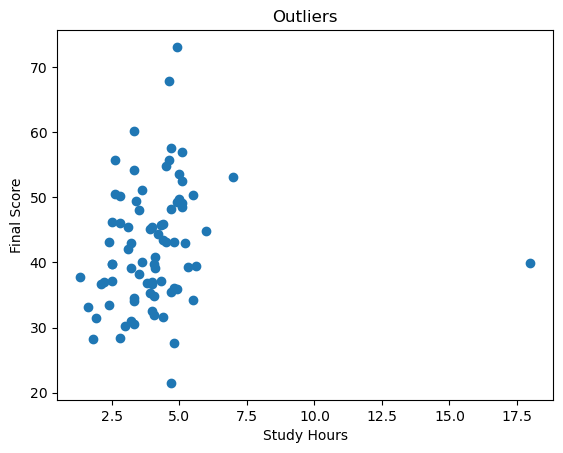

In [14]:
# identifying outliers using scatter plot 
plt.scatter(data['Study_Hours'], data['Final_Score'])
plt.title('Outliers'); plt.xlabel('Study Hours'); plt.ylabel('Final Score')
plt.show()

In [15]:
# encoding categorical variables using LabelEncoder
for col in ['Parental_Support', 'Internet_Access', 'Extracurricular', 'Result']:
    if col in data.columns:
        data[col] = LabelEncoder().fit_transform(data[col].astype(str))

In [16]:
# feature engineering: creating a new feature 'High_Study' based on 'Study_Hours'
data['High_Study'] = (data['Study_Hours'] > 5).astype(int)

In [17]:
# train-test split (drop Student_ID and Final_Score to prevent target leakage)
X = data.drop(columns=['Student_ID', 'Final_Score', 'Result'], errors='ignore')
y = data['Result']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
# feature scaling using MinMaxScaler
scaler = MinMaxScaler()
X_tr_sc, X_te_sc = scaler.fit_transform(X_tr), scaler.transform(X_te)

In [19]:
# feature selection to find the top 4 important features
top_idx = DecisionTreeClassifier(random_state=42).fit(X_tr_sc, y_tr).feature_importances_.argsort()[-4:]

In [22]:
# model training and evaluation
model = DecisionTreeClassifier(class_weight='balanced', random_state=42).fit(X_tr_sc[:, top_idx], y_tr)
preds = model.predict(X_te_sc[:, top_idx])

print("Accuracy:", accuracy_score(y_te, preds))
print("Confusion Matrix:\n", confusion_matrix(y_te, preds))

Accuracy: 0.625
Confusion Matrix:
 [[2 4]
 [2 8]]


In [23]:
# view the cleaned and processed data to a new excel file
data.to_excel('cleaned_student_performance.xlsx', index=False)
print("Cleaned data successfully saved to 'cleaned_student_performance.xlsx'")

Cleaned data successfully saved to 'cleaned_student_performance.xlsx'
